# 07 · Transmon + readout cavity: spectrum and branch analysis (App. A, Fig. 13)

Undriven part of Eq. (70), with the paper's parameters: $E_C/h=280$ MHz, $E_J/E_C=50$, $\omega_r/2\pi=7.5$ GHz, $g/2\pi=250$ MHz, transmon kept in its first $2^{R_t}=32$ eigenstates (charge cutoff $|n|\le 80$ here; the paper uses 500, which changes nothing for 32 levels).

This notebook needs no tensor network: it is a dense diagonalisation, and it produces
* the dressed-state labels $|\overline{i_t,i_c}\rangle$ used as initial states in notebook 08,
* the drive frequency of Eq. (74) (paper: $\omega_d/2\pi=7.522$ GHz),
* the branches of Fig. 13 against which the driven trajectories of Fig. 12a are compared.

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


In [2]:
p = TRANSMON_PARAMS
Et, nt = dr.transmon_eigbasis(p["EC"], p["EJ_over_EC"] * p["EC"], 32, ncut=80)
print(f"f01 = {Et[1]:.4f} GHz   (paper's estimate sqrt(8 EC EJ) - EC = {np.sqrt(8*p['EC']*p['EJ_over_EC']*p['EC']) - p['EC']:.3f} GHz)")
print(f"anharmonicity = {1e3*(Et[2] - 2*Et[1]):.1f} MHz")
small = transmon_cavity_model(32, 12)
lab, _ = dressed_states(small, 2, 2)
wd = 0.5 * sum(lab[(i, 1)][0] - lab[(i, 0)][0] for i in range(2)) / (2 * np.pi)
chi_disp = ((lab[(1, 1)][0] - lab[(1, 0)][0]) - (lab[(0, 1)][0] - lab[(0, 0)][0])) / (2 * np.pi)
print(f"omega_d/2pi = {wd:.4f} GHz  (paper: 7.522)    dispersive shift 2chi/2pi = {1e3*chi_disp:.2f} MHz")

f01 = 5.3037 GHz   (paper's estimate sqrt(8 EC EJ) - EC = 5.320 GHz)
anharmonicity = -321.8 MHz
omega_d/2pi = 7.5218 GHz  (paper: 7.522)    dispersive shift 2chi/2pi = -11.26 MHz


## Fig. 13 — branches in the $(N_c, N_t)$ plane

Labelling (Eqs. A1–A2): the state with the largest overlap with the bare $|i_t,0\rangle$ starts branch $i_t$; then $|\overline{i_t,i_c+1}\rangle$ is the unlabelled eigenstate with the largest overlap with $a^\dagger|\overline{i_t,i_c}\rangle$. Each branch is drawn parametrically, $N_c$ horizontally and $N_t$ vertically. Without drive and coupling every branch would be a horizontal line; jumps mark avoided crossings with highly excited transmon states — the seeds of ionisation.

[diagonalise D = 3840] 256.00 s


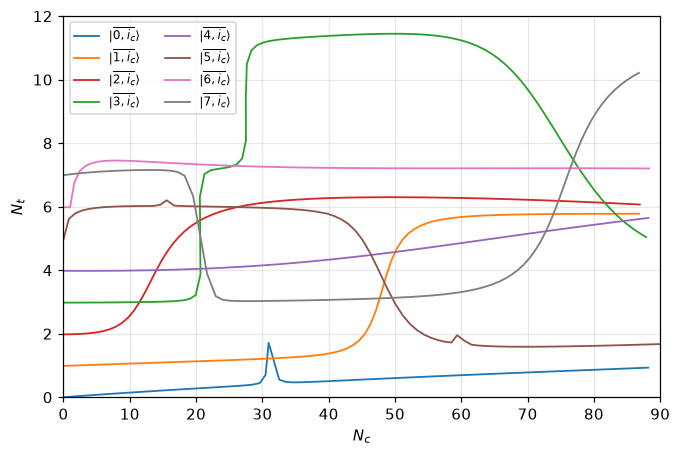

In [3]:
n_c = 120 if not PAPER_SIZE else 200
model = transmon_cavity_model(32, n_c)
with timer(f"diagonalise D = {32 * n_c}"):
    branches, _ = dressed_states(model, n_branches=8, n_c_max=n_c - 30)
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["C0", "C1", "C3", "C2", "C4", "C5", "C6", "C7"]
for it in range(8):
    pts = np.array([branches[(it, ic)][1:] for ic in range(n_c - 30)])   # (Nt, Nc)
    ax.plot(pts[:, 1], pts[:, 0], "-", color=colors[it], lw=1.2, label=rf"$|\overline{{{it},i_c}}\rangle$")
ax.set(xlabel=r"$N_c$", ylabel=r"$N_t$", xlim=(0, n_c - 30), ylim=(0, 12)); ax.legend(ncol=2, fontsize=8)
savefig(fig, "fig13_branches.png"); plt.show()
np.save(os.path.join(FIGDIR, "branches_Nt_Nc.npy"),
        np.array([[branches[(it, ic)][1:] for ic in range(n_c - 30)] for it in range(8)]))

Expected reading (paper, App. A): the $|\overline{0,i_c}\rangle$ branch (blue) climbs slowly, whereas $|\overline{1,i_c}\rangle$ (orange) and $|\overline{2,i_c}\rangle$ (red) meet a crossing with a highly populated branch at a few tens of photons, where $N_t$ jumps. Where branches swap abruptly the labelling is ill-defined (the paper draws those links in grey); with a larger cavity cutoff the high-$N_c$ part of each branch converges. The arrays are saved to `figures/branches_Nt_Nc.npy` for notebook 08.